# HJNC 자부두 환적 타임라인 정리 및 총 소요시간 분석

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
DGT_DGT_CSV_PATH = './data/HJNC_HJNC_2025.csv'
df = pd.read_csv(DGT_DGT_CSV_PATH)

In [11]:
df

,컨테이너번호,Class,적/공,Size/Type,화물종류,중량(kg),Seal No,BL No,양하항,적하항,...,양하모선항차,적하모선명,적하모선항차,선내위치,야드 장치 시간,트럭 진입 시간,온샤시 시간,경과료 Free Date,냉동료 Free Date,반출예정일
0,AMFU3209195,NaN,F,20/GE(2210),NaN,30180,EU29863955,MEDUSO043138,CNSHK,KRPUS,...,NaN,MSC NOA ARIELA,MNOL-001/2025,41-14-02,2025-10-18 17:29,NaN,2025-10-19 16:45,NaN,NaN,NaN
1,AMFU8816550,NaN,F,40/GE(4510),NaN,30258,702588,MEDUVC838533,CNSHK,KRPUS,...,NaN,MSC JULIETTE,MJUT-001/2025,26-09-02,2025-10-03 21:15,NaN,2025-10-05 01:35,NaN,NaN,NaN
2,ARDU2344736,NaN,F,20/GE(2210),NaN,7500,YMAT487430,YMJAW237045150,CAVA5,KRPUS,...,NaN,YM ORCHID,YORD-002/2025,55-14-12,2025-05-31 03:32,NaN,2025-06-01 18:31,2025-06-14 23:59,NaN,NaN
3,ASIU9288070,NaN,M,40/RF(4530),NaN,4735,NOSEAL,RTMF22069300,CNTAO,KRPUS,...,NaN,ONE COSMOS,OMST-004/2025,34-16-90,2025-10-01 23:32,NaN,2025-10-03 15:44,2025-09-30 23:59,NaN,NaN
4,ASIU9290014,NaN,M,40/RF(4530),NaN,4735,NOSEAL,RTMF22069300,CNTAO,KRPUS,...,NaN,ONE COSMOS,OMST-004/2025,34-14-90,2025-10-02 00:25,NaN,2025-10-03 15:46,2025-10-01 23:59,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3164,YMMU6692583,NaN,F,40/GE(4500),NaN,27900,YMAT458281,YMJAW237045177,CAVA1,KRPUS,...,NaN,YM ORCHID,YORD-002/2025,18-07-14,2025-05-31 22:48,NaN,2025-06-02 01:31,2025-06-14 23:59,NaN,NaN
3165,YMMU6711831,NaN,F,40/GE(4500),NaN,28630,YMAT483983,YMJAW237044414,CAVA1,KRPUS,...,NaN,YM ORCHID,YORD-002/2025,18-08-10,2025-06-01 17:26,NaN,2025-06-02 00:56,2025-06-15 23:59,NaN,NaN
3166,YMMU6793850,NaN,F,40/GE(4500),NaN,27990,YMAT483982,YMJAW237044414,CAVA1,KRPUS,...,NaN,YM ORCHID,YORD-002/2025,18-09-12,2025-06-01 00:37,NaN,2025-06-02 01:15,2025-06-15 23:59,NaN,NaN
3167,YMMU6927224,NaN,F,40/GE(4500),NaN,24800,YMAS373307,NaN,NLRTM,KRPUS,...,NaN,HMM ROTTERDAM,HORO-001/2025,30-04-18,2025-03-24 21:40,NaN,2025-03-29 10:11,2025-04-07 23:59,NaN,NaN


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3169 entries, 0 to 3168
Data columns (total 32 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   컨테이너번호         3169 non-null   str    
 1   Class          0 non-null      float64
 2   적/공            3169 non-null   str    
 3   Size/Type      3169 non-null   str    
 4   화물종류           0 non-null      float64
 5   중량(kg)         3169 non-null   int64  
 6   Seal No        3158 non-null   str    
 7   BL No          2894 non-null   str    
 8   양하항            3169 non-null   str    
 9   적하항            3169 non-null   str    
 10  야드위치           3169 non-null   str    
 11  반입방식           3169 non-null   str    
 12  반입시간           3169 non-null   str    
 13  반출방식           3169 non-null   str    
 14  반출시간           3169 non-null   str    
 15  반입차량번호         3138 non-null   str    
 16  반출차량번호         0 non-null      float64
 17  손상여부           10 non-null     str    
 18  IMDG           187 

In [13]:
df.isna().sum()

컨테이너번호              0
Class            3169
적/공                 0
Size/Type           0
화물종류             3169
중량(kg)              0
Seal No            11
BL No             275
양하항                 0
적하항                 0
야드위치                0
반입방식                0
반입시간                0
반출방식                0
반출시간                0
반입차량번호             31
반출차량번호           3169
손상여부             3159
IMDG             2982
UNNO             2982
온도               3064
양하모선명            3138
양하모선항차           3138
적하모선명               0
적하모선항차              0
선내위치                0
야드 장치 시간            0
트럭 진입 시간         3169
온샤시 시간              0
경과료 Free Date    2681
냉동료 Free Date    3169
반출예정일            3169
dtype: int64

In [14]:
pd.DataFrame({
    '자료형' : df.dtypes.astype('str'),
    '비결측수' : df.notna().sum(),
    '결측수' : df.isna().sum(),
    '결측률(%)' : df.isna().mean() * 100,
    '고유값 수' : df.nunique(dropna=True) # 결측치는 빼고 구하겠다.
})

,자료형,비결측수,결측수,결측률(%),고유값 수
컨테이너번호,str,3169,0,0.000000,3138
Class,float64,0,3169,100.000000,0
적/공,str,3169,0,0.000000,2
Size/Type,str,3169,0,0.000000,16
화물종류,float64,0,3169,100.000000,0
중량(kg),int64,3169,0,0.000000,1660
Seal No,str,3158,11,0.347113,3137
BL No,str,2894,275,8.677816,657
양하항,str,3169,0,0.000000,37
적하항,str,3169,0,0.000000,1


In [15]:
df.columns

Index(['컨테이너번호', 'Class', '적/공', 'Size/Type', '화물종류', '중량(kg)', 'Seal No',
       'BL No', '양하항', '적하항', '야드위치', '반입방식', '반입시간', '반출방식', '반출시간', '반입차량번호',
       '반출차량번호', '손상여부', 'IMDG', 'UNNO', '온도', '양하모선명', '양하모선항차', '적하모선명',
       '적하모선항차', '선내위치', '야드 장치 시간', '트럭 진입 시간', '온샤시 시간', '경과료 Free Date',
       '냉동료 Free Date', '반출예정일'],
      dtype='str')

In [18]:
# 공컨테이너는 환적 과정에서의 병목을 파악하기에 부적절하므로 제외하고 적컨으로만 분석 진행
full_con = df[df['적/공'] == 'F']
print(full_con)

           컨테이너번호  Class 적/공    Size/Type  화물종류  중량(kg)     Seal No  \
0     AMFU3209195    NaN   F  20/GE(2210)   NaN   30180  EU29863955   
1     AMFU8816550    NaN   F  40/GE(4510)   NaN   30258      702588   
2     ARDU2344736    NaN   F  20/GE(2210)   NaN    7500  YMAT487430   
10    AXIU2170316    NaN   F  20/GE(2210)   NaN   25300  EU28399651   
11    AXIU2194637    NaN   F  20/GE(2210)   NaN   23920  EU29660276   
...           ...    ...  ..          ...   ...     ...         ...   
3164  YMMU6692583    NaN   F  40/GE(4500)   NaN   27900  YMAT458281   
3165  YMMU6711831    NaN   F  40/GE(4500)   NaN   28630  YMAT483983   
3166  YMMU6793850    NaN   F  40/GE(4500)   NaN   27990  YMAT483982   
3167  YMMU6927224    NaN   F  40/GE(4500)   NaN   24800  YMAS373307   
3168  YMMU6942804    NaN   F  40/GE(4500)   NaN    9560  YMAT071639   

               BL No    양하항    적하항  ... 양하모선항차           적하모선명         적하모선항차  \
0       MEDUSO043138  CNSHK  KRPUS  ...    NaN  MSC NOA ARIELA  MN

In [19]:
# 분석에 필요 없는 컬럼 모두 제거
df_time = full_con[['컨테이너번호', '반입시간', '야드 장치 시간', '온샤시 시간', '반출시간']].copy()
df_time

,컨테이너번호,반입시간,야드 장치 시간,온샤시 시간,반출시간
0,AMFU3209195,2025-10-18 17:23,2025-10-18 17:29,2025-10-19 16:45,2025-10-19 17:03
1,AMFU8816550,2025-10-03 21:10,2025-10-03 21:15,2025-10-05 01:35,2025-10-05 01:45
2,ARDU2344736,2025-05-31 03:25,2025-05-31 03:32,2025-06-01 18:31,2025-06-01 18:44
10,AXIU2170316,2025-10-14 01:55,2025-10-14 02:12,2025-10-17 01:19,2025-10-17 01:26
11,AXIU2194637,2025-10-18 11:40,2025-10-18 11:51,2025-10-19 09:54,2025-10-19 10:05
...,...,...,...,...,...
3164,YMMU6692583,2025-05-31 22:45,2025-05-31 22:48,2025-06-02 01:31,2025-06-02 01:41
3165,YMMU6711831,2025-06-01 17:23,2025-06-01 17:26,2025-06-02 00:56,2025-06-02 01:17
3166,YMMU6793850,2025-06-01 00:29,2025-06-01 00:37,2025-06-02 01:15,2025-06-02 01:24
3167,YMMU6927224,2025-03-24 21:28,2025-03-24 21:40,2025-03-29 10:11,2025-03-29 10:18


In [20]:
# 계산을 위해 반입시간, 반출시간, 온샤시 시간, 야드 장치 시간 자료 형식 날짜로 변경
df_time['반입시간'] = pd.to_datetime(df_time['반입시간'])
df_time['반출시간'] = pd.to_datetime(df_time['반출시간'])
df_time['온샤시 시간'] = pd.to_datetime(df_time['온샤시 시간'])
df_time['야드 장치 시간'] = pd.to_datetime(df_time['야드 장치 시간'])

In [21]:
df_time.info()

<class 'pandas.DataFrame'>
Index: 3141 entries, 0 to 3168
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   컨테이너번호    3141 non-null   str           
 1   반입시간      3141 non-null   datetime64[us]
 2   야드 장치 시간  3141 non-null   datetime64[us]
 3   온샤시 시간    3141 non-null   datetime64[us]
 4   반출시간      3141 non-null   datetime64[us]
dtypes: datetime64[us](4), str(1)
memory usage: 147.2 KB


In [22]:
# 반입시간과 반출시간 모두 2025년 1월 1일 ~ 2025년 12월 31일 안에 있는 데이터만 추출

start_date = '2025-01-01 00:00:00'
end_date = '2025-12-31 23:59:59'

filtered_df = df_time[
    (df_time['반입시간'] >= start_date) & (df_time['반입시간'] <= end_date) &
    (df_time['반출시간'] >= start_date) & (df_time['반출시간'] <= end_date)
]

filtered_df.shape

(3141, 5)

### 각 공정별 작업시간 구하기

In [23]:
# 공정A. 양하~장치 (야드 장치 시간 - 반입시간)
filtered_df['공정A(양하~장치)'] = filtered_df['야드 장치 시간'] - filtered_df['반입시간']
print(filtered_df)

           컨테이너번호                반입시간            야드 장치 시간              온샤시 시간  \
0     AMFU3209195 2025-10-18 17:23:00 2025-10-18 17:29:00 2025-10-19 16:45:00   
1     AMFU8816550 2025-10-03 21:10:00 2025-10-03 21:15:00 2025-10-05 01:35:00   
2     ARDU2344736 2025-05-31 03:25:00 2025-05-31 03:32:00 2025-06-01 18:31:00   
10    AXIU2170316 2025-10-14 01:55:00 2025-10-14 02:12:00 2025-10-17 01:19:00   
11    AXIU2194637 2025-10-18 11:40:00 2025-10-18 11:51:00 2025-10-19 09:54:00   
...           ...                 ...                 ...                 ...   
3164  YMMU6692583 2025-05-31 22:45:00 2025-05-31 22:48:00 2025-06-02 01:31:00   
3165  YMMU6711831 2025-06-01 17:23:00 2025-06-01 17:26:00 2025-06-02 00:56:00   
3166  YMMU6793850 2025-06-01 00:29:00 2025-06-01 00:37:00 2025-06-02 01:15:00   
3167  YMMU6927224 2025-03-24 21:28:00 2025-03-24 21:40:00 2025-03-29 10:11:00   
3168  YMMU6942804 2025-05-31 23:31:00 2025-05-31 23:36:00 2025-06-02 03:45:00   

                    반출시간   

In [24]:
# 공정A의 평균 시간
mean_process_a = filtered_df['공정A(양하~장치)'].mean().floor('s')
print(mean_process_a)

0 days 00:08:01


In [25]:
# 공정B. 장치~온샤시 (온샤시 시간 - 야드 장치 시간)
filtered_df['공정B(장치~온샤시)'] = filtered_df['온샤시 시간'] - filtered_df['야드 장치 시간']
print(filtered_df)

           컨테이너번호                반입시간            야드 장치 시간              온샤시 시간  \
0     AMFU3209195 2025-10-18 17:23:00 2025-10-18 17:29:00 2025-10-19 16:45:00   
1     AMFU8816550 2025-10-03 21:10:00 2025-10-03 21:15:00 2025-10-05 01:35:00   
2     ARDU2344736 2025-05-31 03:25:00 2025-05-31 03:32:00 2025-06-01 18:31:00   
10    AXIU2170316 2025-10-14 01:55:00 2025-10-14 02:12:00 2025-10-17 01:19:00   
11    AXIU2194637 2025-10-18 11:40:00 2025-10-18 11:51:00 2025-10-19 09:54:00   
...           ...                 ...                 ...                 ...   
3164  YMMU6692583 2025-05-31 22:45:00 2025-05-31 22:48:00 2025-06-02 01:31:00   
3165  YMMU6711831 2025-06-01 17:23:00 2025-06-01 17:26:00 2025-06-02 00:56:00   
3166  YMMU6793850 2025-06-01 00:29:00 2025-06-01 00:37:00 2025-06-02 01:15:00   
3167  YMMU6927224 2025-03-24 21:28:00 2025-03-24 21:40:00 2025-03-29 10:11:00   
3168  YMMU6942804 2025-05-31 23:31:00 2025-05-31 23:36:00 2025-06-02 03:45:00   

                    반출시간   

In [26]:
# 공정B 의 평균 시간
mean_process_b = filtered_df['공정B(장치~온샤시)'].mean().floor('s')
print(mean_process_b)

2 days 07:20:08


In [27]:
# 공정C. 온샤시~반출 (반출시간 - 온샤시 시간)
filtered_df['공정C(온샤시~반출)'] = filtered_df['반출시간'] - filtered_df['온샤시 시간']
print(filtered_df)

           컨테이너번호                반입시간            야드 장치 시간              온샤시 시간  \
0     AMFU3209195 2025-10-18 17:23:00 2025-10-18 17:29:00 2025-10-19 16:45:00   
1     AMFU8816550 2025-10-03 21:10:00 2025-10-03 21:15:00 2025-10-05 01:35:00   
2     ARDU2344736 2025-05-31 03:25:00 2025-05-31 03:32:00 2025-06-01 18:31:00   
10    AXIU2170316 2025-10-14 01:55:00 2025-10-14 02:12:00 2025-10-17 01:19:00   
11    AXIU2194637 2025-10-18 11:40:00 2025-10-18 11:51:00 2025-10-19 09:54:00   
...           ...                 ...                 ...                 ...   
3164  YMMU6692583 2025-05-31 22:45:00 2025-05-31 22:48:00 2025-06-02 01:31:00   
3165  YMMU6711831 2025-06-01 17:23:00 2025-06-01 17:26:00 2025-06-02 00:56:00   
3166  YMMU6793850 2025-06-01 00:29:00 2025-06-01 00:37:00 2025-06-02 01:15:00   
3167  YMMU6927224 2025-03-24 21:28:00 2025-03-24 21:40:00 2025-03-29 10:11:00   
3168  YMMU6942804 2025-05-31 23:31:00 2025-05-31 23:36:00 2025-06-02 03:45:00   

                    반출시간   

In [28]:
# 공정C 의 평균 시간
mean_process_c = filtered_df['공정C(온샤시~반출)'].mean().floor('s')
print(mean_process_c)

0 days 00:12:09


In [30]:
# 총 소요시간 구하기
filtered_df['총소요시간'] = (filtered_df['반출시간'] - filtered_df['반입시간']).dt.total_seconds() / 3600  # 시간 단위
# 만약 '분(minute)' 단위로 구하고 싶다면 아래 주석처럼 60으로 나누거나 .dt.total_seconds() / 60을 사용하세요
# df['총소요시간'] = (df['반출시간'] - df['반입시간']).dt.total_seconds() / 60  # 분 단위

print(filtered_df)

           컨테이너번호                반입시간            야드 장치 시간              온샤시 시간  \
0     AMFU3209195 2025-10-18 17:23:00 2025-10-18 17:29:00 2025-10-19 16:45:00   
1     AMFU8816550 2025-10-03 21:10:00 2025-10-03 21:15:00 2025-10-05 01:35:00   
2     ARDU2344736 2025-05-31 03:25:00 2025-05-31 03:32:00 2025-06-01 18:31:00   
10    AXIU2170316 2025-10-14 01:55:00 2025-10-14 02:12:00 2025-10-17 01:19:00   
11    AXIU2194637 2025-10-18 11:40:00 2025-10-18 11:51:00 2025-10-19 09:54:00   
...           ...                 ...                 ...                 ...   
3164  YMMU6692583 2025-05-31 22:45:00 2025-05-31 22:48:00 2025-06-02 01:31:00   
3165  YMMU6711831 2025-06-01 17:23:00 2025-06-01 17:26:00 2025-06-02 00:56:00   
3166  YMMU6793850 2025-06-01 00:29:00 2025-06-01 00:37:00 2025-06-02 01:15:00   
3167  YMMU6927224 2025-03-24 21:28:00 2025-03-24 21:40:00 2025-03-29 10:11:00   
3168  YMMU6942804 2025-05-31 23:31:00 2025-05-31 23:36:00 2025-06-02 03:45:00   

                    반출시간   

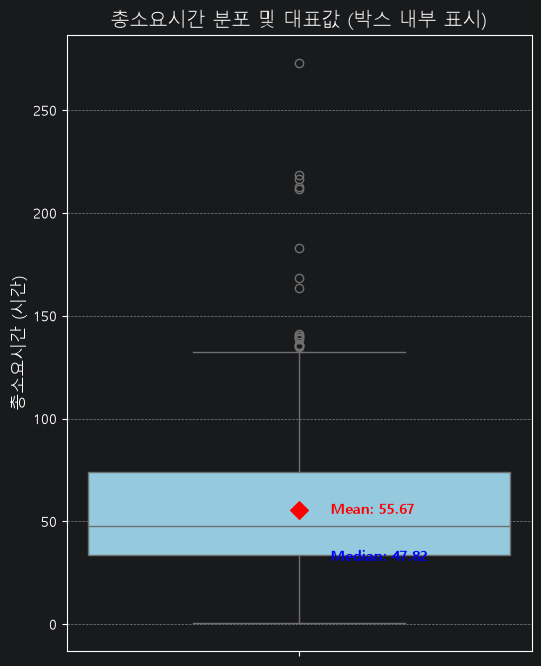

In [32]:
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 평균값과 중앙값 계산
mean_val = filtered_df['총소요시간'].mean()
median_val = filtered_df['총소요시간'].median()

# 2. 박스플롯 그리기
plt.figure(figsize=(6, 8))
ax = sns.boxplot(y=filtered_df['총소요시간'], color='skyblue', width=0.4)

# 3. 평균값 마커와 텍스트를 박스 내부(x=0 근처)로 배치
plt.scatter(0, mean_val, color='red', marker='D', s=80, zorder=5)
# x 좌표를 0.03 정도로 주어 박스 안쪽 왼편에 텍스트가 위치하도록 설정
plt.text(0.03, mean_val, f'Mean: {mean_val:.2f}', color='red', va='center', fontweight='bold', fontsize=10)

# 4. 중앙값 텍스트도 박스 내부 중앙선 근처에 배치
# 중앙값 선(median_val)보다 살짝 위나 아래로 여백을 주어 겹치지 않게 조절 가능합니다.
plt.text(0.03, median_val - 15, f'Median: {median_val:.2f}', color='blue', va='center', fontweight='bold', fontsize=10)

# 5. 그래프 꾸미기
plt.title('총소요시간 분포 및 대표값 (박스 내부 표시)', fontsize=14)
plt.ylabel('총소요시간 (시간)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

## 정리

공정A(양하 ~ 장치)의 평균 작업 시간 : 8분 1초

공정B(장치 ~ 온샤시)의 평균 작업 시간 : 2일 7시간 20분 8초

공정C(온샤시 ~ 반출)의 평균 작업 시간 : 12분 9초

총소요시간(시간) : 평균 55.67, 중앙값 47.82